### Recovering the symbol from a travelling fKdV waves

In [28]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

In [29]:
from solvers.spectral import fKdVNewton
from solvers.pde import fKdV
from solvers.lsm import LSM
from solvers.help import *

from waves.waveGen import fKdVPacket

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [30]:
P           = 2* np.pi
amps = np.linspace(0.01,1,7)
means = np.zeros_like(amps)

N           = 2**6
alpha = 2

dt = 1e-4
T = 1

In [31]:
x = np.linspace(0,P,N)

In [32]:
kdvp = fKdVPacket(P=P,N=N,amp_list=amps, mean_list=means, dt = dt, T= T, alpha=2)
H = kdvp.mainloop()

In [33]:
lsm = LSM(eta_list=H, dt = dt, P = P)
X = lsm.lsm()

In [34]:
ell, n = lsm.fit_symbol()
print(fit_table(ell,n,part='real'))


          ξ^3       ξ^2       ξ^1        ξ^0
ell -0.001382 -0.097922  0.641083 -65.771444
n    0.000037  0.006091 -0.003449   1.999678


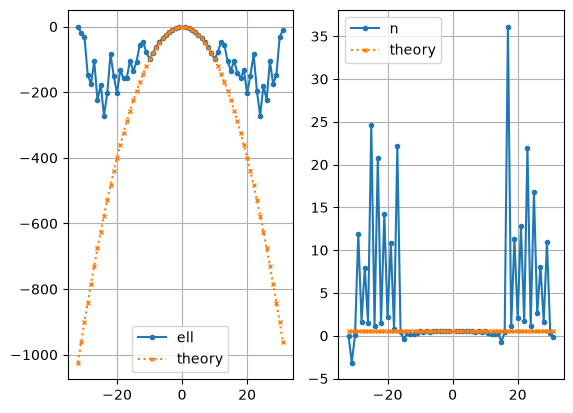

In [35]:
# f = fKdV(P=P,dt=dt,T=T,u0 = H[0][0], alpha=alpha)

lsm.plot_symbol_fit(ell_t=fKdVDispersion(alpha))

C:\Users\henri\AppData\Local\Temp\ipykernel_17748\3012844814.py:14: RuntimeWarning: invalid value encountered in divide
  ell_diff = np.abs((ellt_pos - ell_pos)/ellt_pos)


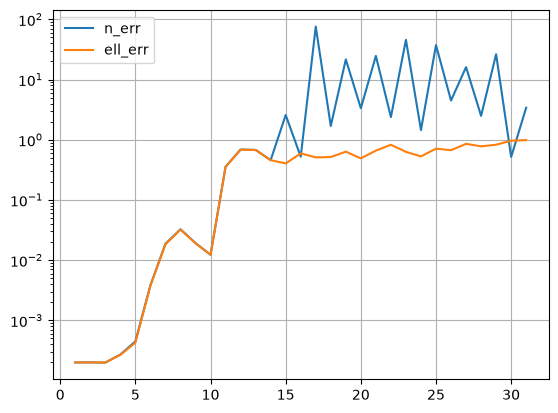

In [ ]:
# We assume the symbols are symmetric
k = lsm.k
order = np.argsort(k)
ko = k[order]
ko_p = ko[N//2:]

nt_pos = n_theory(ko_p)
n_pos = lsm.n[order][N//2:]

ellt_pos = fKdVDispersion(alpha)(ko_p)
ell_pos = lsm.ell[order][N//2:]

n_diff = np.abs((nt_pos - n_pos)/nt_pos)
ell_diff = np.abs((ellt_pos - ell_pos)/ellt_pos)

plt.semilogy(ko_p, n_diff, label = "n_err")
plt.semilogy(ko_p, ell_diff, label = "ell_err")
plt.legend()
plt.grid()
plt.show()